RECIPE YANG ADA DI BUKU

1. Recipe audit station CSV.

 Buat draft recipe untuk audit QA/QC station CSV.
Problem: periksa schema, time range, missing value, dan duplicate timestamp
tanpa mengubah raw input.
Input: [CSV_PATH], time column [TIME_COLUMN], unit contract [UNITS].
Output: Markdown report di [REPORT_PATH] dan run-record schema di [RUN_PATH].
Sertakan minimal theory, prompt reusable, Python implementation plan,
expected checks, failure behavior, dan status Not yet executed sampai
command serta output tersedia

2. Recipe normalisasi GeoJSON.

Susun recipe untuk mengubah [GEOJSON_PATH] menjadi normalized GeoJSON,
inventory CSV, dan summary JSON tanpa kehilangan Feature ID, geometry,
properties, null geometry, atau coordinate order.
Nyatakan CRS/axis/vertical contract yang diketahui; jika tidak tersedia,
minta clarification dan jangan menebaknya. Sertakan structural checks,
topology limits, output paths, and no-network constraint. Pisahkan draft
specification dari claim bahwa output sudah executed.

3.  Recipe model difusi panas satu dimensi.

 Buat draft recipe untuk mensimulasikan difusi panas satu dimensi dengan
initial profile [INITIAL_PROFILE], diffusivity [ALPHA], boundary conditions
[BOUNDARIES], grid [DZ], dan time step [DT].
Sertakan governing equation, unit and sign conventions, stability check,
analytic or baseline comparison, configuration schema, output profile,
figure, run record, serta warning jika parameter atau compiler belum ada.
Jangan mengklaim calibration, convergence, atau execution tanpa evidence.

### CODE IMPLEMENTASI RECIPE 1: AUDIT STATION CSV

In [15]:
import pandas as pd
import json
import os
from datetime import datetime

# 1. DEFINISI FUNGSI AUDIT
def run_qaqc_audit(csv_path: str, time_column: str, units_contract: dict, report_path: str, run_path: str):
    if not os.path.exists(csv_path):
        raise FileNotFoundError(f"File CSV tidak ditemukan pada path: {csv_path}")

    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        raise RuntimeError(f"Gagal membaca file CSV: {str(e)}")

    if time_column not in df.columns:
        raise KeyError(f"Kolom timestamp '{time_column}' tidak ditemukan dalam CSV.")

    total_rows = len(df)

    # Schema Check
    schema_results = []
    for col, expected_unit in units_contract.items():
        if col not in df.columns:
            schema_results.append({"column": col, "expected": expected_unit, "status": "MISSING_COLUMN"})
        else:
            actual_dtype = str(df[col].dtype)
            schema_results.append({
                "column": col,
                "expected_unit": expected_unit,
                "actual_dtype": actual_dtype,
                "status": "OK"
            })

    # Time Range & Continuity Check
    time_series = pd.to_datetime(df[time_column], errors='coerce')
    invalid_timestamps = int(time_series.isna().sum())
    valid_times = time_series.dropna()
    min_time = str(valid_times.min()) if not valid_times.empty else None
    max_time = str(valid_times.max()) if not valid_times.empty else None

    # Missing Value Analysis
    missing_analysis = {}
    for col in df.columns:
        null_cnt = int(df[col].isna().sum())
        missing_analysis[col] = {
            "missing_count": null_cnt,
            "missing_percentage": round((null_cnt / total_rows) * 100, 2) if total_rows > 0 else 0
        }

    # Duplicate Timestamp Check
    duplicate_rows = df[df.duplicated(subset=[time_column], keep=False)]
    duplicate_count = int(df.duplicated(subset=[time_column]).sum())

    # Output 1: Run-Record JSON
    run_record = {
        "execution_timestamp": datetime.now().isoformat(),
        "input_csv": csv_path,
        "time_column": time_column,
        "total_records": total_rows,
        "invalid_timestamps": invalid_timestamps,
        "min_timestamp": min_time,
        "max_timestamp": max_time,
        "duplicate_timestamps_count": duplicate_count,
        "schema_checks": schema_results,
        "missing_values": missing_analysis,
        "status": "SUCCESS"
    }

    os.makedirs(os.path.dirname(os.path.abspath(run_path)), exist_ok=True)
    with open(run_path, "w", encoding="utf-8") as f:
        json.dump(run_record, f, indent=4)

    # Output 2: Markdown Report
    os.makedirs(os.path.dirname(os.path.abspath(report_path)), exist_ok=True)
    md_content = f"""# QA/QC Station CSV Audit Report

**File Input:** `{csv_path}`
**Waktu Eksekusi:** {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}
**Total Rekaman:** {total_rows}

---

## 1. Time Range & Continuity Check
- **Kolom Timestamp:** `{time_column}`
- **Rentang Waktu Awal:** `{min_time}`
- **Rentang Waktu Akhir:** `{max_time}`
- **Timestamp Tidak Valid:** {invalid_timestamps}

---

## 2. Duplicate Timestamp Check
- **Jumlah Duplikat Timestamp:** `{duplicate_count}`
"""
    if duplicate_count > 0:
        md_content += "\n### Contoh Sample Timestamp Duplikat:\n"
        md_content += duplicate_rows[[time_column]].head(10).to_markdown(index=False) + "\n"

    md_content += """
---

## 3. Schema & Unit Contract Verification
| Kolom | Ekspektasi Unit | Dtype Terdeteksi | Status |
|---|---|---|---|
"""
    for res in schema_results:
        exp = res.get('expected_unit', '-')
        dtype = res.get('actual_dtype', 'N/A')
        stat = res.get('status', 'OK')
        md_content += f"| `{res['column']}` | `{exp}` | `{dtype}` | `{stat}` |\n"

    md_content += """
---

## 4. Missing Value Analysis
| Kolom | Jumlah Missing | Persentase (%) |
|---|---|---|
"""
    for col, data in missing_analysis.items():
        md_content += f"| `{col}` | {data['missing_count']} | {data['missing_percentage']}% |\n"

    with open(report_path, "w", encoding="utf-8") as f:
        f.write(md_content)

    print(f"[Recipe 1] Audit Sukses!\nReport disimpan di: {report_path}\nRun-record disimpan di: {run_path}\n")

# 2. MEMBUAT SAMPLE INPUT & MENJALANKAN AUDIT
os.makedirs("data", exist_ok=True)
dummy_csv_path = "data/station_raw.csv"
df_sample = pd.DataFrame({
    "timestamp": ["2023-10-27T08:00:00Z", "2023-10-27T09:00:00Z", "2023-10-27T09:00:00Z", "invalid_time", "2023-10-27T11:00:00Z"],
    "temperature": [25.4, 26.1, 26.1, None, 27.2],
    "humidity": [60, 58, None, 50, 52]
})
df_sample.to_csv(dummy_csv_path, index=False)

# Eksekusi
run_qaqc_audit(
    csv_path=dummy_csv_path,
    time_column="timestamp",
    units_contract={"timestamp": "ISO8601", "temperature": "Celsius", "humidity": "Percentage"},
    report_path="output/qaqc_report.md",
    run_path="output/run_record.json"
)

# Print Hasil Teks Report langsung di output
with open("output/qaqc_report.md", "r", encoding="utf-8") as f:
    print(f.read())

[Recipe 1] Audit Sukses!
Report disimpan di: output/qaqc_report.md
Run-record disimpan di: output/run_record.json

# QA/QC Station CSV Audit Report

**File Input:** `data/station_raw.csv`  
**Waktu Eksekusi:** 2026-10-20 15:33:26  
**Total Rekaman:** 5  

---

## 1. Time Range & Continuity Check
- **Kolom Timestamp:** `timestamp`
- **Rentang Waktu Awal:** `2023-10-27 08:00:00+00:00`
- **Rentang Waktu Akhir:** `2023-10-27 11:00:00+00:00`
- **Timestamp Tidak Valid:** 1

---

## 2. Duplicate Timestamp Check
- **Jumlah Duplikat Timestamp:** `1`

### Contoh Sample Timestamp Duplikat:
| timestamp            |
|:---------------------|
| 2023-10-27T09:00:00Z |
| 2023-10-27T09:00:00Z |

---

## 3. Schema & Unit Contract Verification
| Kolom | Ekspektasi Unit | Dtype Terdeteksi | Status |
|---|---|---|---|
| `timestamp` | `ISO8601` | `object` | `OK` |
| `temperature` | `Celsius` | `float64` | `OK` |
| `humidity` | `Percentage` | `float64` | `OK` |

---

## 4. Missing Value Analysis
| Kolom | Jum

### CODE IMPLEMENTASI RECIPE 2: NORMALISASI GEOJSON

In [16]:
import json
import os
import pandas as pd

# 1. DEFINISI FUNGSI NORMALISASI GEOJSON
def normalize_geojson(geojson_path: str, output_geojson_path: str, inventory_csv_path: str, summary_json_path: str, expected_crs: str = "EPSG:4326"):
    if not os.path.exists(geojson_path):
        raise FileNotFoundError(f"File GeoJSON tidak ditemukan di: {geojson_path}")

    with open(geojson_path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    if data.get("type") != "FeatureCollection":
        raise ValueError("Format GeoJSON harus bertipe 'FeatureCollection'.")

    features = data.get("features", [])
    normalized_features = []
    inventory_records = []
    null_geom_count = 0
    geom_types = {}

    crs_info = data.get("crs", None)
    if crs_info:
        print(f"[WARNING] Informasi CRS non-standar ditemukan: {crs_info}.")

    for idx, feature in enumerate(features):
        feat_id = feature.get("id", f"feat_{idx}")
        geom = feature.get("geometry", None)
        properties = feature.get("properties", {})

        if geom is None or geom.get("coordinates") is None:
            null_geom_count += 1
            geom_type = "Null"
        else:
            geom_type = geom.get("type", "Unknown")

        geom_types[geom_type] = geom_types.get(geom_type, 0) + 1

        inv_entry = {"feature_id": feat_id, "geometry_type": geom_type}
        for k, v in properties.items():
            inv_entry[f"prop_{k}"] = str(v)
        inventory_records.append(inv_entry)

        normalized_features.append({
            "type": "Feature",
            "id": feat_id,
            "geometry": geom,
            "properties": properties
        })

    normalized_collection = {
        "type": "FeatureCollection",
        "crs": {"type": "name", "properties": {"name": f"urn:ogc:def:crs:OGC:1.3:{expected_crs}"}},
        "features": normalized_features
    }

    os.makedirs(os.path.dirname(os.path.abspath(output_geojson_path)), exist_ok=True)
    with open(output_geojson_path, 'w', encoding='utf-8') as f:
        json.dump(normalized_collection, f, indent=4)

    df_inventory = pd.DataFrame(inventory_records)
    os.makedirs(os.path.dirname(os.path.abspath(inventory_csv_path)), exist_ok=True)
    df_inventory.to_csv(inventory_csv_path, index=False)

    summary_data = {
        "total_features": len(features),
        "null_geometries": null_geom_count,
        "geometry_types": geom_types,
        "target_crs": expected_crs,
        "status": "SUCCESS"
    }
    os.makedirs(os.path.dirname(os.path.abspath(summary_json_path)), exist_ok=True)
    with open(summary_json_path, 'w', encoding='utf-8') as f:
        json.dump(summary_data, f, indent=4)

    print(f"[Recipe 2] Normalisasi Sukses!\nGeoJSON: {output_geojson_path}\nInventory: {inventory_csv_path}\nSummary: {summary_json_path}\n")

# 2. MEMBUAT SAMPLE INPUT & MENJALANKAN NORMALISASI
os.makedirs("data", exist_ok=True)
sample_geojson_path = "data/dummy_map.geojson"
sample_geojson = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "id": "monumen_01",
            "geometry": {"type": "Point", "coordinates": [106.8271, -6.1751]},
            "properties": {"name": "Monas", "city": "Jakarta"}
        },
        {
            "type": "Feature",
            "geometry": None,
            "properties": {"name": "Unknown Landmark", "city": "Unknown"}
        }
    ]
}

with open(sample_geojson_path, 'w', encoding='utf-8') as f:
    json.dump(sample_geojson, f)

# Eksekusi
normalize_geojson(
    geojson_path=sample_geojson_path,
    output_geojson_path="output/normalized_map.geojson",
    inventory_csv_path="output/properties_inventory.csv",
    summary_json_path="output/geojson_summary.json"
)

# Tampilkan isi Summary JSON hasil eksekusi
with open("output/geojson_summary.json", "r") as f:
    print("--- ISI SUMMARY JSON ---")
    print(json.dumps(json.load(f), indent=2))

[Recipe 2] Normalisasi Sukses!
GeoJSON: output/normalized_map.geojson
Inventory: output/properties_inventory.csv
Summary: output/geojson_summary.json

--- ISI SUMMARY JSON ---
{
  "total_features": 2,
  "null_geometries": 1,
  "geometry_types": {
    "Point": 1,
    "Null": 1
  },
  "target_crs": "EPSG:4326",
  "status": "SUCCESS"
}


### CODE IMPLEMENTASI RECIPE 3: MODEL DIFUSI PANAS 1D

Fourier Number (Kriteria Stabilitas): 0.0800
[INFO] Konfigurasi aman dan stabil.


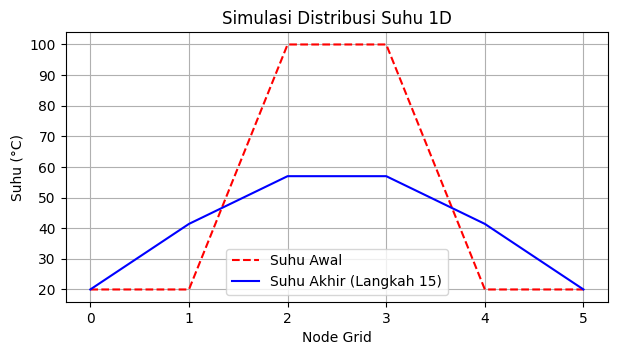

[Recipe 3] Simulasi selesai! Run-record disimpan di: output/heat_diffusion_run.json



In [17]:
import numpy as np
import matplotlib.pyplot as plt
import json
import os

# 1. DEFINISI FUNGSI DIFUSI PANAS
def run_heat_diffusion_1d(initial_temp: list, alpha: float, boundaries: tuple, dz: float, dt: float, timesteps: int, run_path: str):
    fourier_number = alpha * dt / (dz ** 2)
    print(f"Fourier Number (Kriteria Stabilitas): {fourier_number:.4f}")

    if fourier_number > 0.5:
        print(f"[WARNING] Fourier number {fourier_number:.4f} > 0.5! Hasil simulasi tidak stabil/divergen.")
    else:
        print("[INFO] Konfigurasi aman dan stabil.")

    T = np.array(initial_temp, dtype=float)
    nodes = len(T)
    history = [T.copy().tolist()]

    for step in range(timesteps):
        T_new = T.copy()
        T_new[0] = boundaries[0]
        T_new[-1] = boundaries[1]
        for i in range(1, nodes - 1):
            T_new[i] = T[i] + fourier_number * (T[i+1] - 2*T[i] + T[i-1])
        T = T_new.copy()
        history.append(T.tolist())

    # Menampilkan Plot/Figure
    plt.figure(figsize=(7, 3.5))
    plt.plot(initial_temp, 'r--', label='Suhu Awal')
    plt.plot(T, 'b-', label=f'Suhu Akhir (Langkah {timesteps})')
    plt.title("Simulasi Distribusi Suhu 1D")
    plt.xlabel("Node Grid")
    plt.ylabel("Suhu (°C)")
    plt.legend()
    plt.grid(True)
    plt.show()

    run_record = {
        "alpha": alpha,
        "dz": dz,
        "dt": dt,
        "fourier_number": fourier_number,
        "stable": bool(fourier_number <= 0.5),
        "initial": initial_temp,
        "final": T.tolist(),
        "timesteps": timesteps
    }

    os.makedirs(os.path.dirname(os.path.abspath(run_path)), exist_ok=True)
    with open(run_path, 'w', encoding='utf-8') as f:
        json.dump(run_record, f, indent=4)
    print(f"[Recipe 3] Simulasi selesai! Run-record disimpan di: {run_path}\n")

# 2. EKSEKUSI SIMULASI
run_heat_diffusion_1d(
    initial_temp=[20.0, 20.0, 100.0, 100.0, 20.0, 20.0],
    alpha=0.01,
    boundaries=(20.0, 20.0),
    dz=0.5,
    dt=2.0,
    timesteps=15,
    run_path="output/heat_diffusion_run.json"
)